<a href="https://colab.research.google.com/github/Martinmbiro/student-knn-task/blob/main/00_scikit_learn_question_solution_github.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **scikit-learn question solution**
🔔 **Tip**  
> Please refer to this notebook and the slides together

## Data Wrangling
> 🔔 **Note**  

> Data wrangling, also known as data munging or data preparation, is the process of cleaning, structuring, and transforming raw, complex, or inconsistent data into a usable format for analysis, AI, or machine learning

In [ ]:
# imports
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import gradio as gr

In [ ]:
# read in the dataset
students = pd.read_excel('/content/student_knn_data-gemini-3.xlsx', engine='openpyxl')

# display dataset summary info
students.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 6 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   No.                    1000 non-null   int64  
 1   Hours_Studied          985 non-null    float64
 2   Attendance_Percentage  985 non-null    float64
 3   Assignments_Completed  1000 non-null   int64  
 4   Past_Exam_Score        985 non-null    float64
 5   Final_Result           1000 non-null   object 
dtypes: float64(3), int64(2), object(1)
memory usage: 47.0+ KB


In [ ]:
# visualize 5 random rows
students.sample(5)

,No.,Hours_Studied,Attendance_Percentage,Assignments_Completed,Past_Exam_Score,Final_Result
518,519,3.6,54.0,7,49.0,FAIL
873,874,5.9,56.0,7,54.0,FAIL
94,95,5.2,94.0,10,38.0,PASS
310,311,1.2,85.0,8,71.0,FAIL
851,852,2.9,54.0,5,90.0,FAIL


In [ ]:
# check total number of null values per column
students.isnull().sum()

,0
No.,0
Hours_Studied,15
Attendance_Percentage,15
Assignments_Completed,0
Past_Exam_Score,15
Final_Result,0


In [ ]:
# print rows for which ANY value is NULL (NaN)
# boolean indexing:
students[students.isnull().any(axis=1)]

,No.,Hours_Studied,Attendance_Percentage,Assignments_Completed,Past_Exam_Score,Final_Result
57,58,2.6,42.0,10,NaN,FAIL
66,67,NaN,99.0,4,NaN,FAIL
125,126,5.5,96.0,3,NaN,FAIL
161,162,4.4,NaN,7,97.0,PASS
183,184,NaN,64.0,4,47.0,PASS
192,193,NaN,68.0,5,35.0,FAIL
219,220,NaN,92.0,7,83.0,PASS
221,222,NaN,98.0,7,66.0,FAIL
319,320,8.8,43.0,9,NaN,PASS
331,332,7.4,81.0,5,NaN,PASS


In [ ]:
# drop rows with null values, drop the No. colum
students.drop(columns=['No.'], inplace=True) # drop column
students.dropna(inplace=True) # drop rows with null values

# get info on new DataFrame
students.info()

<class 'pandas.core.frame.DataFrame'>
Index: 956 entries, 0 to 999
Data columns (total 5 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Hours_Studied          956 non-null    float64
 1   Attendance_Percentage  956 non-null    float64
 2   Assignments_Completed  956 non-null    int64  
 3   Past_Exam_Score        956 non-null    float64
 4   Final_Result           956 non-null    object 
dtypes: float64(3), int64(1), object(1)
memory usage: 44.8+ KB


## Exploratory Data Analysis (EDA)
> 🔔 **Note**  

> The critical initial process of analyzing, visualizing, and summarizing datasets to understand their structure, uncover patterns, detect anomalies, and test assumptions before building models

### Check the target / label column

In [ ]:
# check unique count in target column
students['Final_Result'].value_counts()

,count
Final_Result,
FAIL,492
PASS,464


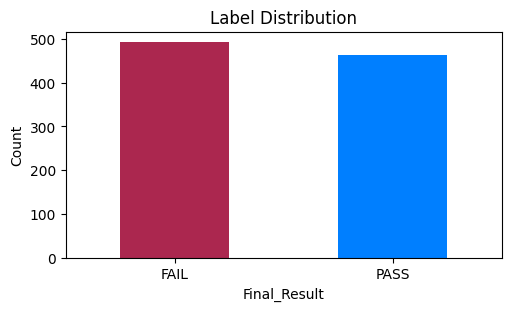

In [ ]:
# plot that on a bar plt
f, ax = plt.subplots(figsize=(5,3), layout='compressed')
# plot the Series above
students['Final_Result'].value_counts().plot.bar(ax=ax, color=['#AB274F', '#007FFF'])

ax.set_title('Label Distribution') # set plot title
ax.set_ylabel('Count') # xaxis label
ax.xaxis.set_tick_params(labelrotation=0) # make xaxis ticks (PASS, FAIL) horizontal

plt.show()

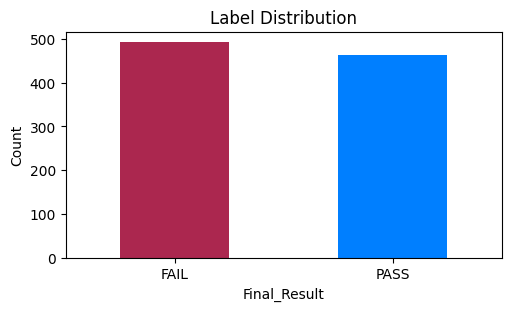

In [ ]:
# plot that on a bar plt
plt.figure(figsize=(5,3), layout='compressed')
# plot the Series above
students['Final_Result'].value_counts().plot.bar(color=['#AB274F', '#007FFF'],
                                                 rot=0)
# rot = 0 argument above ensures xaxis ticks (PASS, FAIL) appear horizontal

plt.title('Label Distribution') # set plot title
plt.ylabel('Count') # xaxis label

plt.show()

### Check correlation between the label & other columns
+ Since the label is categorical (`FAIL` vs `PASS`) and other columns are numerical, we shall use a `boxplot` to visualize correlation between the columns and label

In [ ]:
# column names
students.columns

Index(['Hours_Studied', 'Attendance_Percentage', 'Assignments_Completed',
       'Past_Exam_Score', 'Final_Result'],
      dtype='object')

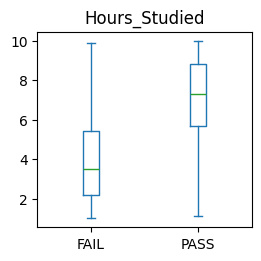

In [ ]:
# visualize relationship for one column (Hours_Studied)
f, ax = plt.subplots(figsize=(2.5,2.5), layout='compressed')
students.plot.box(by='Final_Result', column=['Hours_Studied'], ax=ax)
plt.show()

In [ ]:
# list of column names
cols = students.columns[:-1]
cols

Index(['Hours_Studied', 'Attendance_Percentage', 'Assignments_Completed',
       'Past_Exam_Score'],
      dtype='object')

In [ ]:
# list of column names
cols = ['Hours_Studied', 'Attendance_Percentage', 'Assignments_Completed',
       'Past_Exam_Score']

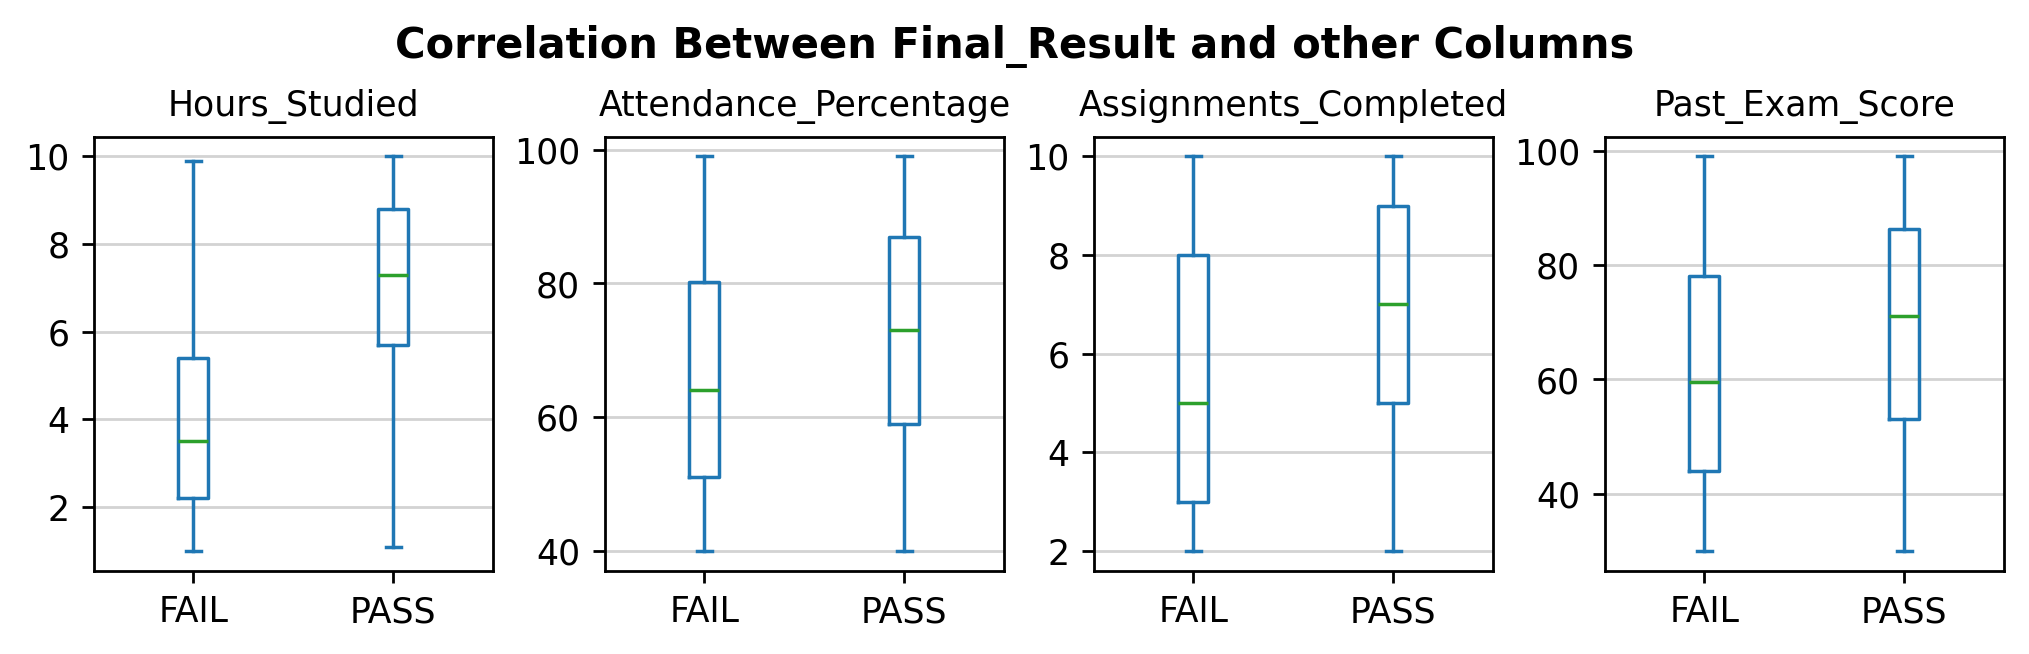

In [ ]:
# define figure and subplots
f, axs = plt.subplots(nrows=1, ncols=len(cols), figsize=(8, 2.5), layout='compressed', dpi=250)

# use a for loop to plot in all Axes in axs
for i, ax, in enumerate(axs):
  students.plot.box(by='Final_Result', column=cols[i], ax=ax)
  ax.set_title(cols[i], fontsize=10)
  ax.grid(axis='y', color='lightgray')

# suptitle
f.suptitle('Correlation Between Final_Result and other Columns', weight='black')
plt.show()

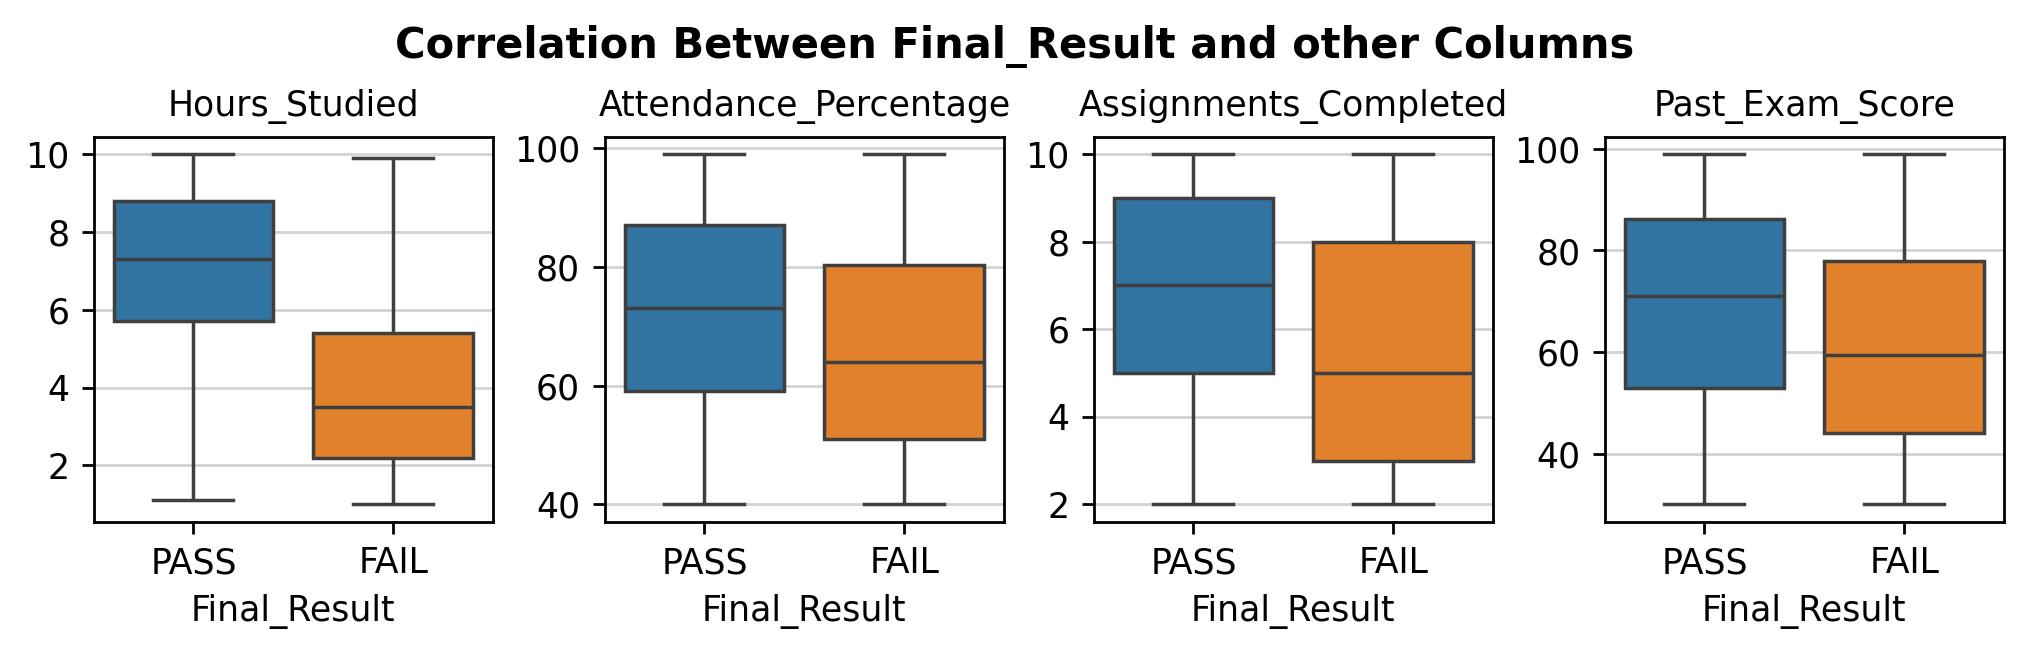

In [ ]:
f, axs = plt.subplots(nrows=1, ncols=len(cols), figsize=(8, 2.5), layout='compressed', dpi=250)

# use a for loop to plot in all Axes in axs
for i, ax, in enumerate(axs):
  sns.boxplot(data=students, x='Final_Result', y=cols[i], ax=ax, hue='Final_Result', legend=False)
  ax.set_title(cols[i], fontsize=10)
  ax.grid(axis='y', color='lightgray')
  ax.set_ylabel('')

# suptitle
f.suptitle('Correlation Between Final_Result and other Columns', weight='black')
plt.show()

### Encode the label
> The label is in words. However, ML models do not understand words, but rather numbers

In [ ]:
students.head()

,Hours_Studied,Attendance_Percentage,Assignments_Completed,Past_Exam_Score,Final_Result
0,9.0,97.0,6,58.0,PASS
1,4.0,89.0,8,36.0,FAIL
2,6.8,71.0,10,54.0,PASS
3,3.0,68.0,8,48.0,FAIL
4,4.2,74.0,3,88.0,FAIL


#### Using [`Series.replace`](https://pandas.pydata.org/docs/reference/api/pandas.Series.replace.html#pandas-series-replace)

In [ ]:
# --- APPROACH 1: Series.replace() ----
# overwrite values in label column with results from transformed values
students['Final_Result'] = students['Final_Result']\
                              .replace({'FAIL': '0', 'PASS': '1'})\
                              .astype(int)

# visualize first 5 rows
students.head(5)

,Hours_Studied,Attendance_Percentage,Assignments_Completed,Past_Exam_Score,Final_Result
0,9.0,97.0,6,58.0,1
1,4.0,89.0,8,36.0,0
2,6.8,71.0,10,54.0,1
3,3.0,68.0,8,48.0,0
4,4.2,74.0,3,88.0,0


#### Using [`LabelEncoder`](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.LabelEncoder.html#labelencoder)

In [ ]:
# --- APPROACH 2: LabelEncoder ----
from sklearn.preprocessing import LabelEncoder

# initialize an object of LabelEncoder
le = LabelEncoder()

# overwrite values in label column with results from transformed values
students['Final_Result'] = le.fit_transform(students['Final_Result'])

# visualize first 5 rows
students.head(5)

,Hours_Studied,Attendance_Percentage,Assignments_Completed,Past_Exam_Score,Final_Result
0,9.0,97.0,6,58.0,1
1,4.0,89.0,8,36.0,0
2,6.8,71.0,10,54.0,1
3,3.0,68.0,8,48.0,0
4,4.2,74.0,3,88.0,0


#### Using [`Series.apply`](https://pandas.pydata.org/docs/reference/api/pandas.Series.replace.html#pandas-series-replace) and a lambda function

In [ ]:
# --- APPROACH 3: Series.apply() ----
def encoder_func(x: str) -> int:
  return 1 if x == 'PASS' else 0

# overwrite values in label column with results from transformed values
students['Final_Result'] = students['Final_Result']\
                                .apply(encoder_func)
                              # .apply(lambda x: 1 if x=='PASS' else 0)

# display first 5 rows
students.head(5)

,Hours_Studied,Attendance_Percentage,Assignments_Completed,Past_Exam_Score,Final_Result
0,9.0,97.0,6,58.0,0
1,4.0,89.0,8,36.0,0
2,6.8,71.0,10,54.0,0
3,3.0,68.0,8,48.0,0
4,4.2,74.0,3,88.0,0


#### Using [`Series.map`](https://pandas.pydata.org/docs/reference/api/pandas.Series.map.html#pandas.Series.map) and a `dict` mapper

In [ ]:
# --- APPROACH 4: Series.map() ----
# overwrite values in label column with results from transformed values
students['Final_Result'] = students['Final_Result']\
                                  .map({'PASS':1, 'FAIL':0}, na_action='ignore')

# visualize first 5 rows
students.head(5)

,Hours_Studied,Attendance_Percentage,Assignments_Completed,Past_Exam_Score,Final_Result
0,9.0,97.0,6,58.0,1
1,4.0,89.0,8,36.0,0
2,6.8,71.0,10,54.0,1
3,3.0,68.0,8,48.0,0
4,4.2,74.0,3,88.0,0


### Selecting the features, **X** and label, **y**

In [ ]:
# X - features, y - label or target
X = students[['Hours_Studied', 'Attendance_Percentage', 'Assignments_Completed', 'Past_Exam_Score']]
y = students['Final_Result']

## Splitting into Test and Train sets

In [ ]:
from sklearn.model_selection import train_test_split

# split our features, X, and label, y, into test and train sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42)

In [ ]:
# check size of training set
X_train.shape, y_train.shape

((764, 4), (764,))

In [ ]:
# check size of test set
X_test.shape, y_test.shape

((192, 4), (192,))

## Define `Pipeline` with pre-processing steps

In [ ]:
# imports
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.neighbors import KNeighborsClassifier

In [ ]:
# pipeline object
pipe = Pipeline(steps=[
   #(step name, estimator / transformer)
    ('scaler', StandardScaler()),   # step 1: scaling
    ('knn', KNeighborsClassifier()) # step 2: KNN Classifier
])

# display pipeline as diagram
pipe

Pipeline(steps=[('scaler', StandardScaler()), ('knn', KNeighborsClassifier())])

## Train the model
> Entails fitting the data to the algorithm

### Using `GridSearchCV`

In [ ]:
from sklearn.model_selection import GridSearchCV
from sklearn.model_selection import StratifiedKFold

In [ ]:
# Parameters of pipelines can be set or specified
# using '__' separated by parameter name:
params = {
    'knn__n_neighbors' : np.arange(1,6)
}

# instantiate object
model = GridSearchCV(
    estimator=pipe,
    param_grid=params,
    return_train_score = True,
    scoring='accuracy',
    cv=StratifiedKFold(shuffle=True))

In [ ]:
%%time
# train the model
model.fit(X_train.values, y_train.values)

CPU times: user 453 ms, sys: 0 ns, total: 453 ms
Wall time: 478 ms


GridSearchCV(cv=StratifiedKFold(n_splits=5, random_state=None, shuffle=True),
             estimator=Pipeline(steps=[('scaler', StandardScaler()),
                                       ('knn', KNeighborsClassifier())]),
             param_grid={'knn__n_neighbors': array([1, 2, 3, 4, 5])},
             return_train_score=True, scoring='accuracy')

### Visualize training results

In [ ]:
# plug model.cv_results_ dictionary into a DataFrame
results = pd.DataFrame(model.cv_results_)

# display results DataFrame column names
results.columns

Index(['mean_fit_time', 'std_fit_time', 'mean_score_time', 'std_score_time',
       'param_knn__n_neighbors', 'params', 'split0_test_score',
       'split1_test_score', 'split2_test_score', 'split3_test_score',
       'split4_test_score', 'mean_test_score', 'std_test_score',
       'rank_test_score', 'split0_train_score', 'split1_train_score',
       'split2_train_score', 'split3_train_score', 'split4_train_score',
       'mean_train_score', 'std_train_score'],
      dtype='object')

In [ ]:
# rename column appropriately
results.rename(columns={'param_knn__n_neighbors': 'k_values'}, inplace=True)

# visualize a subset of the DataFrame
results[['k_values', 'mean_test_score', 'mean_train_score']]

,k_values,mean_test_score,mean_train_score
0,1,0.799742,1.000000
1,2,0.768309,0.904447
2,3,0.849467,0.909685
3,4,0.837659,0.889397
4,5,0.863854,0.899866


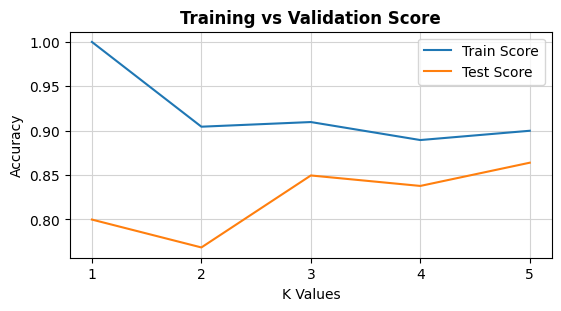

In [ ]:
# create figure & subplot
f, ax = plt.subplots(figsize=(5.5,3), layout='compressed')
# make two plots on the Axes
ax.plot(results['k_values'], results['mean_train_score'], label='Train Score')
ax.plot(results['k_values'], results['mean_test_score'], label='Test Score')

ax.set_title('Training vs Validation Score', weight='black')
ax.set_ylabel('Accuracy')
ax.set_xlabel('K Values')
ax.xaxis.set_ticks(np.arange(1, len(params['knn__n_neighbors'])+1))
ax.legend()
ax.grid(axis='both', color='lightgray')
plt.show()

In [ ]:
# best parameter returned
model.best_params_

{'knn__n_neighbors': np.int64(5)}

In [ ]:
# best estimator returned
model.best_estimator_

Pipeline(steps=[('scaler', StandardScaler()),
                ('knn', KNeighborsClassifier(n_neighbors=np.int64(5)))])

## Evaluate model

### Predict on `X_test`

In [ ]:
# get y_pred
y_pred = model.predict(X_test.values)

# shape of y_pred should be same as y_test:
y_pred.shape, y_test.shape

((192,), (192,))

In [ ]:
# import relevant classification metrics
from sklearn.metrics import (accuracy_score,
                             confusion_matrix,
                             ConfusionMatrixDisplay,
                             classification_report)

### Accuracy

In [ ]:
# calculate accuracy
acc = accuracy_score(y_pred=y_pred, y_true=y_test)

# print
print(f'Model Accuracy: {round(acc, 2)}')

Model Accuracy: 0.86


### Classification report

In [ ]:
# generate classification report
cr = classification_report(y_true=y_test, y_pred=y_pred)

# print
print(cr)

              precision    recall  f1-score   support

           0       0.87      0.86      0.87       103
           1       0.84      0.85      0.85        89

    accuracy                           0.86       192
   macro avg       0.86      0.86      0.86       192
weighted avg       0.86      0.86      0.86       192



### Confusion Matrix

In [ ]:
# generate confusion matrix
cm = confusion_matrix(y_pred=y_pred, y_true=y_test)

# print
print(cm)

[[89 14]
 [13 76]]


### Confusion Matrix Display

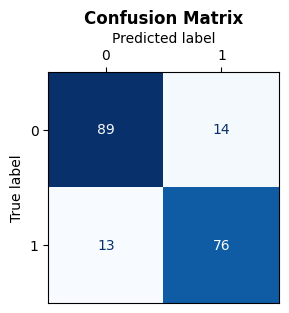

In [ ]:
# create figure & Axes
f, ax = plt.subplots(figsize=(3,3))
ConfusionMatrixDisplay.from_predictions(
        y_true=y_test,
        y_pred=y_pred,
        colorbar=False,
        cmap='Blues',
        ax=ax)

ax.set_title('Confusion Matrix', weight='black')
ax.xaxis.tick_top()                # have ticks appear at the top
ax.xaxis.set_label_position('top') # have xlabel appear at the top
plt.show()

## Program to prompt

In [ ]:
# function to perform inferencing
def predict_results():
  # empty list to store student details
  info = []

  print('WELCOME TO THE STUDENT FINAL RESULT PREDICTION SYSTEM\n')

  # get user input, cast to float
  hours = float(input('Insert Hours Studied\n'))
  attendance = float(input('Insert Student Attendance\n'))
  assgn = float(input('Insert No. of Assignments\n'))
  exam_score = float(input('Insert Previous Exam Score\n'))

  # append user input to the empty list
  info.append([hours, attendance, assgn, exam_score])
  # convert list into numpy array
  x_info = np.array(info)

  # perform inference
  if model.predict(x_info).item() == 1:
    prediction = 'PASS'
  else:
    prediction = 'FAIL'

  # display result
  print(f'\nBased on the Data Entered, the student is likely to {prediction}')


In [ ]:
# call the function
predict_results()

WELCOME TO THE STUDENT FINAL RESULT PREDICTION SYSTEM

Insert Hours Studied
8
Insert Student Attendance
59
Insert No. of Assignments
7
Insert Previous Exam Score
58
(1, 4)

Based on the Data Entered, the student is likely to PASS


## Model Persistence

### Save the model
📝 **Note**  
+ The saved model state object is uploaded to my Hugging Face Model repository linked [here](https://huggingface.co/martinmbiro/student_knn)
+ It will then be reconstructed into a `GridSearchCV` object (dynamically in code) and used to run inference on the user input, once the project is hosted on Hugging Face Spaces


In [ ]:
# import joblib
import joblib

# define file name
file_name = 'knn_model.joblib'

# save the model
joblib.dump(value=model, filename=file_name)

['knn_model.joblib']

### Load the model

In [ ]:
# define path to saved file
file_path = '/content/knn_model.joblib'

# load model
loaded_model = joblib.load(filename=file_path)

In [ ]:
# check type of object loaded
type(loaded_model)

sklearn.model_selection._search.GridSearchCV

## Pre-process the data

In [ ]:
# imports
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

In [ ]:
# read in csv with Null values
games = pd.read_csv('/content/game_stats.csv')
sales = pd.read_csv('/content/sales.csv')

In [ ]:
# display sales
# purely numeric
sales

In [ ]:
bb = np.array([1, 500, 50]).reshape(-1, 3)

In [ ]:
sales['shipping_zip'].median()

In [ ]:
# display games
# both categorical & numeric
games

In [ ]:
# pre-process sales dataset
sales_pipeline = Pipeline(steps=[
    # (name of step, estimator / transformer)
    ('imputer', SimpleImputer(strategy='median')), # step 1
    ('scaler', StandardScaler())                   # step 2
])

# visualize the pipeline object as a diagram
sales_pipeline

In [ ]:
# applying those preprocessing step to sales
sales_pipeline.fit_transform(sales)

In [ ]:
# plug into a dataframe for easier visualization
pd.DataFrame(sales_pipeline.fit_transform(sales.values))

In [ ]:
sales_pipeline

In [ ]:
# transform games dataset
num_transformer = Pipeline(steps=[ # for numerical columns
    # (name of step, estimator / transformer)
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

cat_transformer = Pipeline(steps=[ # for categorical columns
    # (name of step, estimator / transformer)
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('ohe', OneHotEncoder(handle_unknown='ignore'))
])

# combine both transformers
preprocessor = ColumnTransformer(transformers=[
  # (name of step, transformer, [target columns])
    ('cat', cat_transformer, [0,1]),
    ('num', num_transformer, [2,3,4])
])

# display preprocessor as a diagram:
preprocessor

In [ ]:
# applying those preprocessing step to games
preprocessor.fit_transform(games)

In [ ]:
# plug into a dataframe for easier visualization
pd.DataFrame(preprocessor.fit_transform(games))

In [ ]:
aa = np.array(['bob', 'nba', 31, 5, 7])

pd.DataFrame(preprocessor.transform(aa.reshape(-1, 5)))

In [ ]:
pipe.fit_transform(X_train)

## Coding [`gradio`](https://gradio.app/) interface
Here, we'll code the web based user interface for our trained KNN model.
+ The user can input student data, submit the data; then the model will perform inference and return a message back to the user
+ We shall do this using the [`gradio`](https://gradio.app/) framework

#### Model loading

In [ ]:
%%time
import joblib, os
from huggingface_hub import hf_hub_download
from google.colab import userdata

# get model path from huggingface models:
model_path = hf_hub_download(
    repo_id='martinmbiro/student_knn',
    filename='knn_model.joblib',
    token=userdata.get('HF_TOKEN')
  )

# load model from joblib file
model = joblib.load(filename=model_path)

CPU times: user 18.1 ms, sys: 3.2 ms, total: 21.3 ms
Wall time: 906 ms


#### `gradio` App Interface

In [ ]:
import gradio as gr, numpy as np

# function to run model
# takes inputs from UI, returns result
def predict(hours, att, assgn, exam):
  inputs = np.asarray([[hours, att, assgn, exam]])
  if (None in inputs):
    gr.Info('Please fill all student details', duration=4)
    return
  else:
    # make prediction
    pred = 'PASS' if model.predict(inputs).item() == 1 else 'FAIL'

    # return statement with prediction
    return f'The student is likely to {pred}'

# custom CSS
custom_css = """
  #txt {
    text-align: center;
  }

  #prediction textarea {
    font-weight: bold !important;
    font-size: 15px !important;
  }

  #submit_btn {
    font-weight: normal !important;
    color: #000000 !important;
  }

  #clear_btn {
    font-weight: normal !important;
  }
"""

with gr.Blocks() as demo:
  # header
  gr.Markdown(
      """
      ## Predict Student Performance
      > _Enter student details to predict **PASS** or **FAIL**_
      """,
      elem_id='txt'
  )

  # inputs
  with gr.Row():
    hours = gr.Number(label='Hours Studied', minimum=0, maximum=10)
    att = gr.Number(label='Attendance (%)', minimum=0, maximum=100)
    assgn = gr.Number(label='Assignments Submitted', minimum=0, maximum=10)
    exam = gr.Number(label='Previous Exam Score (%)', minimum=0, maximum=100)

  # prediction
  pred_mssg = gr.Textbox(label='Prediction:', elem_id='prediction')

  # buttons
  with gr.Row():
    with gr.Row(scale=1):
        submit = gr.Button('✔️ Submit', variant='primary', size='md', elem_id='submit_btn')
        gr.ClearButton([hours, att, assgn, exam, pred_mssg], value='🗑️ Clear', size='md', elem_id='clear_btn')

    with gr.Column(scale=1):
      pass

  # footer
  gr.Markdown(
      """
      _Find github repository and documentation linked [here](https://github.com/Martinmbiro/student-knn-task)_<br>
      """,
      elem_id='txt'
  )

  submit.click(
      fn=predict,
      inputs=[hours, att, assgn, exam],
      outputs=pred_mssg
  )


demo.queue().launch(css=custom_css)

## Turn code into python modules
Here, we'll organize the most relevant bits of code into `.py` files that can be executed if hosted (say on [Huggingface Spaces](https://huggingface.co/spaces)

📝 **Note**  
We'll only have the following logic in python modules:
1. The [`gradio`](https://gradio.app/) application and inference code - `app.py`  
2. The code to load and deserialize the saved model state object - `model_loader.py`


#### Model loading
Here, we do the following
1. Download the saved model state - `knn_model.joblib` from the Hugging Face Model repository linked [here](https://huggingface.co/martinmbiro/student_knn) using [`huggingface_hub.hf_hub_download`](https://huggingface.co/docs/huggingface_hub/v2.2.0/en/package_reference/file_download#huggingface_hub.hf_hub_download)
2. Deserialize the object using [`joblib`](https://joblib.readthedocs.io/en/stable/)

In [ ]:
!pip install spaces

In [ ]:
# create a .env file with HF_TOKEN
from pathlib import Path
from google.colab import userdata

with Path(Path.cwd().joinpath('.env')).open(mode='w', encoding="utf-8") as f:
  f.write(f'HF_TOKEN={userdata.get('HF_TOKEN')}')

In [ ]:
%%writefile model_loader.py
import joblib
import os
from huggingface_hub import hf_hub_download

"""
________________
FOR COLAB ONLY
_______________
  REMEMBER TO DELETE THESE 2 LINES FOR HUGGINGFACE SPACES

ALSO
____
  demo.launch(share=False)
"""
from dotenv import load_dotenv, find_dotenv
load_dotenv(find_dotenv())

# get model path
model_path = hf_hub_download(
    repo_id='martinmbiro/student_knn',
    filename='knn_model.joblib',
    token=os.environ.get('HF_TOKEN')
  )

# load model from joblib file
model = joblib.load(filename=model_path)

Overwriting model_loader.py


#### `gradio` App Interface

In [ ]:
%%writefile app.py
"""
________________
RECALL RECALL RECAL
_______________
  REMEMBER TO set:

  demo.launch(share=False)
"""
import spaces
import sklearn
import gradio as gr
import numpy as np
from model_loader import model

@spaces.GPU # required for HF Spaces ZeroGPU
def predict(model: sklearn.model_selection.GridSearchCV, inputs: np.ndarray) -> str:
  """Executes the trained model to predict whether a student will PASS or FAIL.

    Parameters
    ----------
    model : sklearn.model_selection.GridSearchCV
        A fitted scikit-learn estimator or GridSearchCV object used for inference.
    inputs : np.ndarray
        A 2D NumPy array of shape (1, 4) containing numerical feature values.

    Returns
    -------
    str
        A formatted string stating whether the student is likely to PASS or FAIL.
  """
  # make prediction
  pred = 'PASS' if model.predict(inputs).item() == 1 else 'FAIL'
  # return statement with prediction
  return f'The student is likely to {pred}'


def on_click(hours: float | None, att: float | None, assgn: float | None, exam: float | None) -> str | None:
  """Handles the UI click event, validating inputs before generating a performance prediction.

    Parameters
    ----------
    hours : float or None
        Number of study hours.
    att : float or None
        Attendance percentage or score.
    assgn : float or None
        Assignment score.
    exam : float or None
        Exam score.

    Returns
    -------
    str or None
        A formatted prediction string ('PASS' or 'FAIL') if all inputs are provided,
        or None if validation fails (a Gradio info notification is displayed).
  """
  inputs = np.asarray([[hours, att, assgn, exam]])
  if (None in inputs):
    gr.Info('Please fill all student details', duration=4)
    return
  else:
    return predict(model, inputs)

# custom CSS
custom_css = """
  #txt {
    text-align: center;
  }

  #prediction textarea {
    font-weight: bold !important;
    font-size: 15px !important;
  }

  #submit_btn {
    font-weight: normal !important;
    color: #000000 !important;
  }

  #clear_btn {
    font-weight: normal !important;
  }
"""

with gr.Blocks() as demo:
  # header
  gr.Markdown(
      """
      ## Predict Student Performance
      > _Enter student details to predict **PASS** or **FAIL**_
      """,
      elem_id='txt'
  )

  # inputs
  with gr.Row():
    hours = gr.Number(label='Hours Studied', minimum=0, maximum=10)
    att = gr.Number(label='Attendance (%)', minimum=0, maximum=100)
    assgn = gr.Number(label='Assignments Submitted', minimum=0, maximum=10)
    exam = gr.Number(label='Previous Exam Score (%)', minimum=0, maximum=100)

  # prediction
  pred_mssg = gr.Textbox(label='Prediction:', elem_id='prediction')

  # buttons
  with gr.Row():
    with gr.Row(scale=1):
        submit = gr.Button('✔️ Submit', variant='primary', size='md', elem_id='submit_btn')
        gr.ClearButton([hours, att, assgn, exam, pred_mssg], value='🗑️ Clear', size='md', elem_id='clear_btn')

    with gr.Column(scale=1):
      pass

  # footer
  gr.Markdown(
      """
      _Find GitHub repository and documentation linked [here](https://github.com/Martinmbiro/student-knn-task)_<br>
      """,
      elem_id='txt'
  )

  submit.click(
      fn=on_click,
      inputs=[hours, att, assgn, exam],
      outputs=pred_mssg
  )

demo.queue().launch(css=custom_css, share=True)

### Python dependencies

In [ ]:
# requirements.txt
requirements = Path.cwd().joinpath('requirements.txt')

with requirements.open(mode='w', encoding="utf-8") as f:
  f.write('scikit-learn\n')
  f.write('numpy\n')
  f.write('joblib')